# Turbofan RUL Prediction — Modeling

From the EDA: 14 of 21 sensors carry degradation signal, FD001 has a single operating condition, and piecewise-linear RUL (cap 125) is the honest target.

Plan: sliding windows of 30 cycles → statistical features per sensor → regressors predicting RUL. We judge with **RMSE** and the **PHM asymmetric score** — which punishes *late* predictions (predicting an engine has longer than it does) harder than early ones. In maintenance, a late prediction can mean an unplanned failure; an early one just means a slightly early inspection.

In [1]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
DATA, FIG = "../data", "../reports/figures"
os.makedirs(FIG, exist_ok=True)
COLS = ["unit", "cycle", "op1", "op2", "op3"] + [f"s{i}" for i in range(1, 22)]
# informative sensors from the EDA screen (|trend corr| > 0.5, non-constant)
SENS = ["s2","s3","s4","s7","s8","s9","s11","s12","s13","s14","s15","s17","s20","s21"]
RUL_MAX, WIN = 125, 30
def load(name):
    return pd.read_csv(f"{DATA}/{name}", sep=r"\s+", header=None, names=COLS)
train = load("train_FD001.txt"); test = load("test_FD001.txt")
rul_test = pd.read_csv(f"{DATA}/RUL_FD001.txt", header=None, names=["rul"])
print("train rows:", len(train), "| engines:", train.unit.nunique())
print("sensors used:", len(SENS))
def phm_score(y_true, y_pred):
    """PHM08 asymmetric scoring: late predictions (d>0) cost more."""
    d = np.asarray(y_pred) - np.asarray(y_true)
    return float(np.sum(np.where(d < 0, np.exp(-d/13)-1, np.exp(d/10)-1)))
def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


train rows: 20631 | engines: 100
sensors used: 14


## 1. Sliding-window features

One row per cycle can't capture *trend* — so we feed each model a 30-cycle window and summarize every informative sensor with six statistics: mean, std, min, max, last value, and slope (linear trend within the window). The label is the piecewise-linear RUL at the window's end.

In [2]:
def window_features(df, win=WIN, stride=1):
    """Build one feature row per sliding window. Label = RUL at window end."""
    rows, labels = [], []
    for u, d in df.groupby("unit"):
        d = d.sort_values("cycle").reset_index(drop=True)
        life = d.cycle.max()
        vals = d[SENS].values
        for end in range(win, len(d)+1, stride):
            w = vals[end-win:end]
            last_cycle = d.cycle.iloc[end-1]
            feat = {}
            for j, s in enumerate(SENS):
                v = w[:, j]
                feat[f"{s}_mean"] = v.mean()
                feat[f"{s}_std"] = v.std()
                feat[f"{s}_min"] = v.min()
                feat[f"{s}_max"] = v.max()
                feat[f"{s}_last"] = v[-1]
                feat[f"{s}_slope"] = np.polyfit(np.arange(win), v, 1)[0]
            rows.append(feat)
            labels.append(min(RUL_MAX, life - last_cycle))
    X = pd.DataFrame(rows)
    return X, np.array(labels)
t0 = time.time()
X_all, y_all = window_features(train)
print(f"windows: {len(X_all):,} | features: {X_all.shape[1]} | built in {time.time()-t0:.0f}s")
print(f"label: mean RUL={y_all.mean():.1f}, share capped at {RUL_MAX}: {(y_all==RUL_MAX).mean():.1%}")
# engine ids per window (for a leak-free split by engine)
units_per_window = []
for u, d in train.groupby("unit"):
    n = (len(d) - WIN)//1 + 1
    units_per_window += [u]*n
units_per_window = np.array(units_per_window)
assert len(units_per_window) == len(X_all)
X_all.head(3).to_string()

windows: 17,731 | features: 84 | built in 16s
label: mean RUL=80.6, share capped at 125: 30.1%


'      s2_mean    s2_std  s2_min  s2_max  s2_last  s2_slope      s3_mean    s3_std   s3_min  s3_max  s3_last  s3_slope      s4_mean    s4_std   s4_min   s4_max  s4_last  s4_slope     s7_mean    s7_std  s7_min  s7_max  s7_last  s7_slope      s8_mean    s8_std  s8_min   s8_max  s8_last  s8_slope      s9_mean    s9_std  s9_min   s9_max  s9_last  s9_slope   s11_mean   s11_std  s11_min  s11_max  s11_last  s11_slope    s12_mean   s12_std  s12_min  s12_max  s12_last  s12_slope     s13_mean   s13_std  s13_min  s13_max  s13_last  s13_slope     s14_mean   s14_std  s14_min  s14_max  s14_last  s14_slope  s15_mean   s15_std  s15_min  s15_max  s15_last  s15_slope    s17_mean   s17_std  s17_min  s17_max  s17_last  s17_slope   s20_mean   s20_std  s20_min  s20_max  s20_last  s20_slope   s21_mean   s21_std  s21_min  s21_max  s21_last  s21_slope\n0  642.328333  0.322977  641.71  643.07   642.20  0.005724  1587.558333  4.045194  1581.11  1594.1  1593.52  0.078547  1400.107333  2.850578  1394.75  1406.22  

## 2. Leak-free split: by engine, not by window

Windows from the same engine overlap — splitting rows randomly would leak. We split 80/20 on *engines* instead.

In [3]:
rng = np.random.default_rng(42)
engines = train.unit.unique()
rng.shuffle(engines)
n_tr = int(0.8*len(engines))
tr_eng, va_eng = set(engines[:n_tr]), set(engines[n_tr:])
tr_m = np.isin(units_per_window, list(tr_eng))
Xtr, ytr = X_all[tr_m], y_all[tr_m]
Xva, yva = X_all[~tr_m], y_all[~tr_m]
print(f"train engines: {len(tr_eng)} -> {len(Xtr):,} windows")
print(f"val   engines: {len(va_eng)} -> {len(Xva):,} windows")

train engines: 80 -> 14,207 windows
val   engines: 20 -> 3,524 windows


## 3. Model comparison

Three regressors: a regularized linear baseline (Ridge), random forest, and histogram gradient boosting. Judged on RMSE and the PHM asymmetric score.

In [4]:
models = {
    "ridge": Ridge(alpha=1.0),
    "rf": RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42),
    "hgb": HistGradientBoostingRegressor(random_state=42),
}
lb = []
fitted = {}
for name, m in models.items():
    t0 = time.time()
    m.fit(Xtr, ytr)
    p = m.predict(Xva)
    lb.append({"model": name, "rmse": rmse(yva, p),
               "phm": phm_score(yva, p), "secs": time.time()-t0})
    fitted[name] = m
lb = pd.DataFrame(lb).sort_values("rmse")
print(lb.round(2).to_string(index=False))
WINNER = lb.iloc[0]["model"]
print("\nwinner:", WINNER)

model  rmse      phm   secs
  hgb 13.88 13006.99   1.98
   rf 14.78 13166.63 162.67
ridge 18.29 16673.21   0.21

winner: hgb


## 4. Reading the winner's errors

A single RMSE hides *where* the model fails. For maintenance planning, errors near end-of-life matter most — so we look at predicted-vs-true and the error distribution.

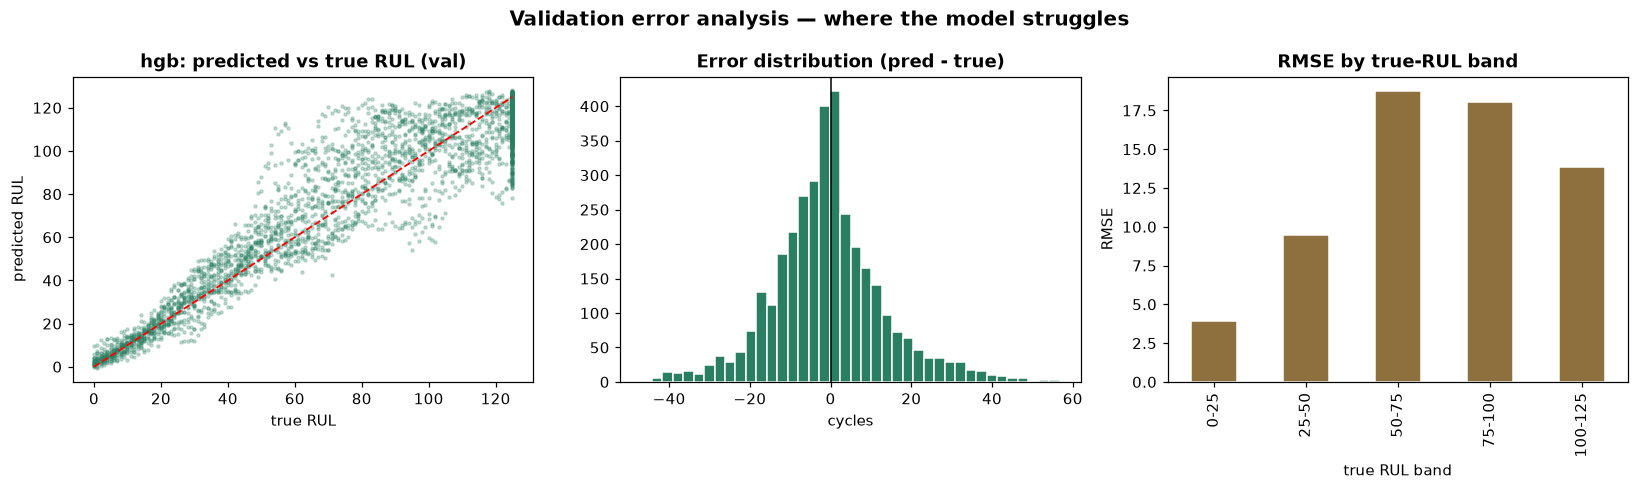

val RMSE: 13.88 | val PHM score: 13007
share of predictions within ±10 cycles: 61.4%
band
0-25        3.90
25-50       9.49
50-75      18.75
75-100     18.05
100-125    13.82


In [5]:
m = fitted[WINNER]
pva = m.predict(Xva)
err = pva - yva
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].scatter(yva, pva, s=4, alpha=0.25, color="#2a7f62")
axes[0].plot([0, RUL_MAX], [0, RUL_MAX], "r--", lw=1.2)
axes[0].set_title(f"{WINNER}: predicted vs true RUL (val)", fontweight="bold")
axes[0].set_xlabel("true RUL"); axes[0].set_ylabel("predicted RUL")
axes[1].hist(err, bins=40, color="#2a7f62", edgecolor="white")
axes[1].axvline(0, color="black", lw=1)
axes[1].set_title("Error distribution (pred - true)", fontweight="bold")
axes[1].set_xlabel("cycles")
# error by true-RUL band: the business-critical view
bands = pd.cut(yva, bins=[0, 25, 50, 75, 100, 125],
               labels=["0-25", "25-50", "50-75", "75-100", "100-125"])
band_rmse = pd.DataFrame({"band": bands, "se": (pva-yva)**2}).groupby("band", observed=True).se.mean().pow(0.5)
band_rmse.plot.bar(ax=axes[2], color="#8e6f3e", edgecolor="white")
axes[2].set_title("RMSE by true-RUL band", fontweight="bold")
axes[2].set_xlabel("true RUL band"); axes[2].set_ylabel("RMSE")
fig.suptitle("Validation error analysis — where the model struggles", fontsize=13,
             fontweight="bold")
fig.tight_layout(); fig.savefig(f"{FIG}/06_val_errors.png", dpi=120); plt.show()
print(f"val RMSE: {rmse(yva, pva):.2f} | val PHM score: {phm_score(yva, pva):.0f}")
print(f"share of predictions within ±10 cycles: {(np.abs(err) <= 10).mean():.1%}")
print(band_rmse.round(2).to_string())

## 5. Test set: the real exam

Each test engine contributes exactly **one** scored point: the window ending at its last observed (truncated) cycle, against the ground-truth RUL file. This mirrors deployment — one prediction per engine, made mid-life.

model  test_rmse  test_phm
  hgb      12.74    247.39
   rf      13.48    306.81
ridge      17.43    484.27


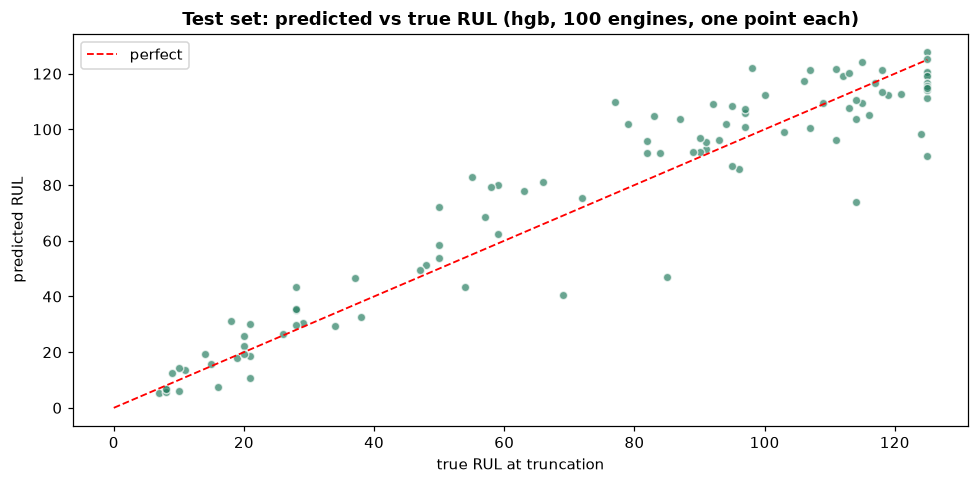


test RMSE (hgb): 12.74 | test PHM score: 247


In [6]:
Xte_all, _ = window_features(test)
# last window per test engine
last_idx = []
pos = 0
for u, d in test.groupby("unit"):
    n = (len(d) - WIN)//1 + 1
    last_idx.append(pos + n - 1)
    pos += n
Xte = Xte_all.iloc[last_idx].reset_index(drop=True)
yte = rul_test.rul.clip(upper=RUL_MAX).values
assert len(Xte) == len(yte) == 100
res = []
for name, mm in fitted.items():
    p = mm.predict(Xte)
    res.append({"model": name, "test_rmse": rmse(yte, p), "test_phm": phm_score(yte, p)})
res = pd.DataFrame(res).sort_values("test_rmse")
print(res.round(2).to_string(index=False))
pw = fitted[WINNER].predict(Xte)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(yte, pw, s=30, alpha=0.7, color="#2a7f62", edgecolors="white")
ax.plot([0, RUL_MAX], [0, RUL_MAX], "r--", lw=1.2, label="perfect")
ax.set_title(f"Test set: predicted vs true RUL ({WINNER}, 100 engines, one point each)",
             fontweight="bold")
ax.set_xlabel("true RUL at truncation"); ax.set_ylabel("predicted RUL"); ax.legend()
fig.tight_layout(); fig.savefig(f"{FIG}/07_test_rul.png", dpi=120); plt.show()
print(f"\ntest RMSE ({WINNER}): {rmse(yte, pw):.2f} | test PHM score: {phm_score(yte, pw):.0f}")

## 6. Which sensors does the model lean on?

Aggregating feature importances back to sensor level — the same 'where to spend instrumentation budget' view as Project #1.

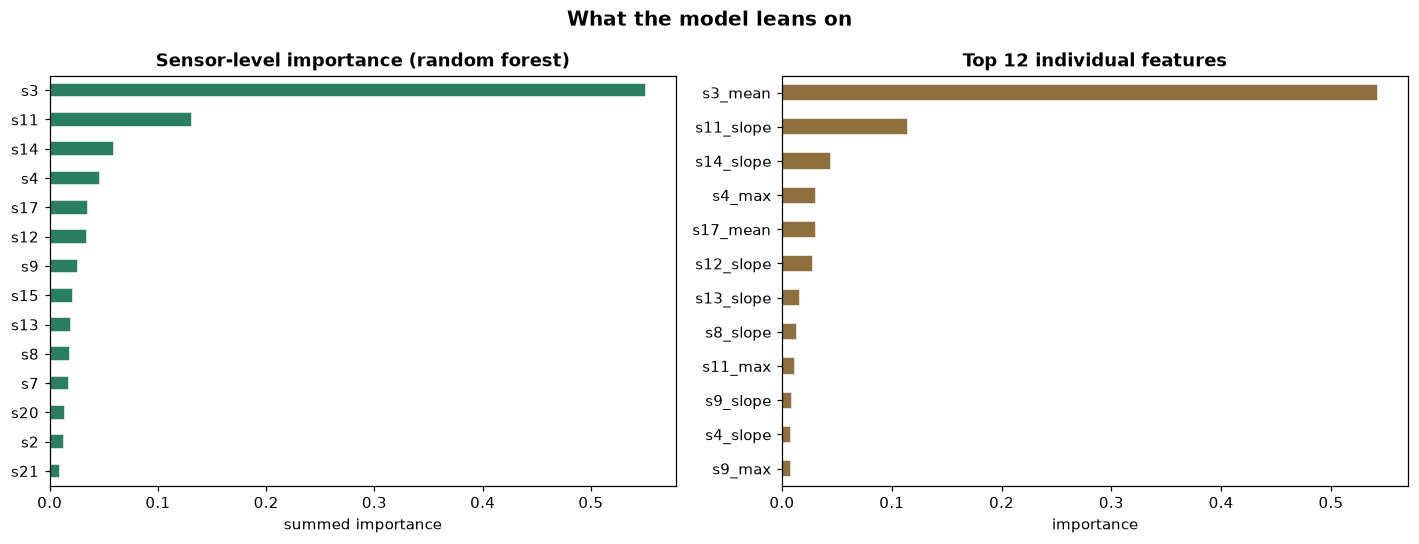

top 5 sensors: ['s3', 's11', 's14', 's4', 's17']


In [7]:
rf = fitted["rf"]
imp = pd.Series(rf.feature_importances_, index=X_all.columns)
by_sensor = imp.groupby(lambda f: f.rsplit("_", 1)[0]).sum().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
by_sensor.plot.barh(ax=axes[0], color="#2a7f62", edgecolor="white")
axes[0].set_title("Sensor-level importance (random forest)", fontweight="bold")
axes[0].set_xlabel("summed importance")
imp.nlargest(12).sort_values().plot.barh(ax=axes[1], color="#8e6f3e", edgecolor="white")
axes[1].set_title("Top 12 individual features", fontweight="bold")
axes[1].set_xlabel("importance")
fig.suptitle("What the model leans on", fontsize=13, fontweight="bold")
fig.tight_layout(); fig.savefig(f"{FIG}/08_importance.png", dpi=120); plt.show()
print("top 5 sensors:", by_sensor.nlargest(5).index.tolist())

## 7. Results, limitations, next steps

**What we built:** sliding-window RUL regression on FD001, judged by RMSE and the business-weighted PHM score.

**Limitations (stated plainly):**
- *Simulated* degradation, not real engines — signal shapes are cleaner than field data.
- FD001 only: single operating condition, single fault mode. FD002–FD004 add regimes and a second fault mode (regime normalization needed).
- Windows are fixed-length summaries, not a learned sequence model (LSTM/Transformer is the natural next step).
- Piecewise-linear cap (125) is a modeling choice, not physics.

**Next:** Project #3 turns RUL into decisions — *replace now / inspect later / keep operating* — with a cost model, which is where the maintenance planner actually lives.

In [8]:
# persist a machine-readable summary for the README
summary = {
    "dataset": "NASA C-MAPSS FD001",
    "window": WIN, "rul_cap": RUL_MAX, "sensors_used": SENS,
    "winner": WINNER,
    "val": {"rmse": rmse(yva, fitted[WINNER].predict(Xva)),
            "phm": phm_score(yva, fitted[WINNER].predict(Xva))},
    "test": {"rmse": float(res[res.model==WINNER].test_rmse.iloc[0]),
             "phm": float(res[res.model==WINNER].test_phm.iloc[0])},
    "leaderboard_val": lb.round(3).to_dict("records"),
}
os.makedirs("../reports", exist_ok=True)
json.dump(summary, open("../reports/metrics.json", "w"), indent=2)
print(json.dumps({k: v for k, v in summary.items() if k != "leaderboard_val"}, indent=2))

{
  "dataset": "NASA C-MAPSS FD001",
  "window": 30,
  "rul_cap": 125,
  "sensors_used": [
    "s2",
    "s3",
    "s4",
    "s7",
    "s8",
    "s9",
    "s11",
    "s12",
    "s13",
    "s14",
    "s15",
    "s17",
    "s20",
    "s21"
  ],
  "winner": "hgb",
  "val": {
    "rmse": 13.880077482052434,
    "phm": 13006.989265796004
  },
  "test": {
    "rmse": 12.736647398351122,
    "phm": 247.39161412590485
  }
}
